## **Summary**

### 1. Data selection and preprocessing

### 2. Selected clustering 1: origin oriented

- 2.1 Cells' features distribution comparison

- 2.2 Vehicles' derived from the clusters trajectory and features visualization

### 3. Selected clustering 2: destiny oriented

- 3.1 Cells' features distribution comparison

- 3.2 Vehicles' derived from the clusters trajectory and features visualization

### 4. Plotting vehicles' features pairs

### Conclusions

In [1]:
import import_first

from common import (deploy_utils, feature_utils, plot_utils, cluster_utils)

from pathlib import PurePath

import time
import numpy as np
import matplotlib.pyplot as plt

import pickle

## **1. Get data**

In [2]:
trace = deploy_utils.Trace.read_trace(
    file_path=PurePath("..") / ".." / "data" / "6_to_8am.csv")
print("trace summary:\n" + deploy_utils.Trace.summarize_trace(trace=trace))

trace summary:
[+] number of vehicles: 75516
[+] number of lines: 2182717
[+] x interval: [0, 99]
[+] y interval: [0, 99]


In [3]:
cell_df = feature_utils.Features.create_basic_cell_df(trace=trace)

In [4]:
cell_df.head()

,start_c,end_c,avg_dwell_time,pop
x:y,,,,
0:43,0,0,26.666667,3
10:28,0,0,10.000000,6
10:29,0,0,10.000000,17
10:32,0,0,12.500000,8
10:33,0,0,43.333333,12


In [5]:
v_df = feature_utils.Features.create_basic_vehicle_df(trace=trace)

In [6]:
v_df.head()

,trip_duration,trip_length,trip_speed,radius_of_gyration,entropy
vehicle_id,,,,,
0,280,16,0.057143,3.166598,3.896292
1,660,35,0.053030,9.093438,4.847520
2,400,27,0.067500,6.107182,4.534184
3,230,14,0.060870,2.945942,3.675311
4,740,41,0.055405,9.749632,5.136696


### 1.1 Preprocessing

In [7]:
cell_df, _ = cluster_utils.Preprocessing.do_standard_scale(df=cell_df, features=cell_df.columns.tolist())

In [8]:
cell_df.head()

,start_c,end_c,avg_dwell_time,pop
x:y,,,,
0:43,-0.733131,-0.449962,0.586733,-0.612063
10:28,-0.733131,-0.449962,-0.846835,-0.608488
10:29,-0.733131,-0.449962,-0.846835,-0.595379
10:32,-0.733131,-0.449962,-0.631800,-0.606104
10:33,-0.733131,-0.449962,2.020302,-0.601338


In [9]:
v_df, _ = cluster_utils.Preprocessing.do_standard_scale(df=v_df, features=v_df.columns.tolist())

In [10]:
v_df.head()

,trip_duration,trip_length,trip_speed,radius_of_gyration,entropy
vehicle_id,,,,,
0,-0.956085,-0.685207,0.686673,-0.692637,-0.222071
1,0.205044,0.323697,0.378576,0.711783,0.675063
2,-0.589413,-0.101105,1.462592,0.004162,0.379546
3,-1.108865,-0.791407,0.965864,-0.744924,-0.430485
4,0.449492,0.642298,0.556510,0.867275,0.947794


In [11]:
# Moving index to column
v_df.reset_index(names="vehicle_id", inplace=True)

In [12]:
v_df.head()

,vehicle_id,trip_duration,trip_length,trip_speed,radius_of_gyration,entropy
0,0,-0.956085,-0.685207,0.686673,-0.692637,-0.222071
1,1,0.205044,0.323697,0.378576,0.711783,0.675063
2,2,-0.589413,-0.101105,1.462592,0.004162,0.379546
3,3,-1.108865,-0.791407,0.965864,-0.744924,-0.430485
4,4,0.449492,0.642298,0.556510,0.867275,0.947794


## **2. Selected clustering 1: origin oriented**

- Features: (start_c, pop)
- k: 3

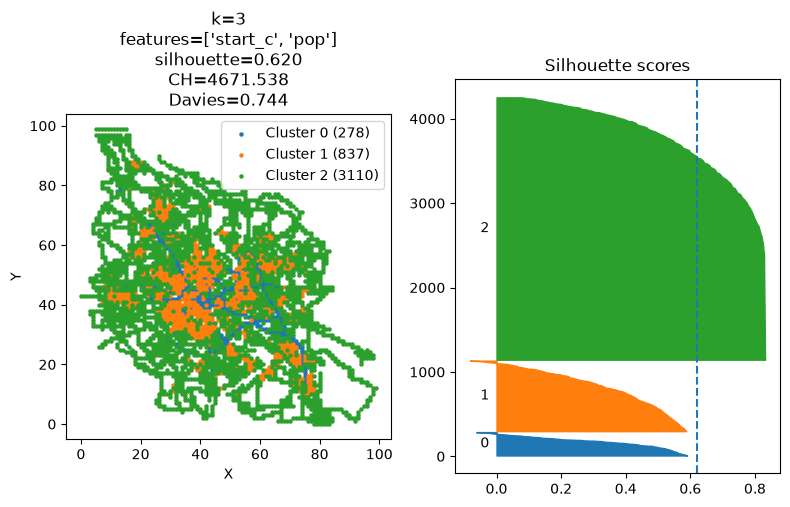

In [13]:
clust_res_1 = cluster_utils.Clustering.run_kmeans(df=cell_df, features=["start_c", "pop"], k=3, n_runs=100)[0]
cluster_utils.Clustering.plot_celldf_clustering_result(result_df=clust_res_1, features=["start_c", "pop"], figsize=(8, 5))
plt.show()

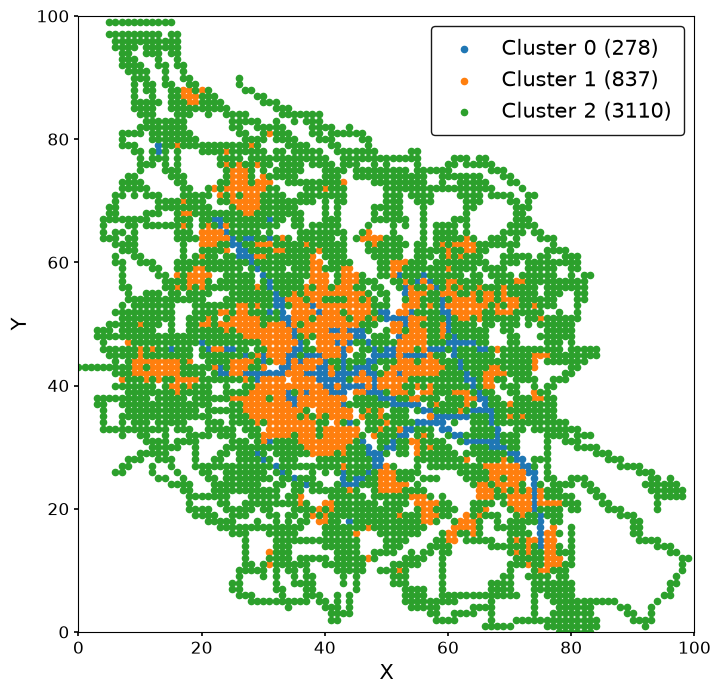

In [30]:
fig, ax = plt.subplots(figsize=(8, 8))

plot_utils.Plot.plot_cell_clusters(
    clusters_dict=cluster_utils.Clustering.clustered_celldf_to_dict(clust_res_1),
    ax=ax
)

ax.tick_params(
    axis="both",
    which="major",
    labelsize=12,
    length=3,
    width=1.2
)

ax.set_xlim(0, 100)
ax.set_ylim(0, 100)

ax.set_xticks([0, 20, 40, 60, 80, 100])
ax.set_yticks([0, 20, 40, 60, 80, 100])

ax.legend(
    loc="upper right",
    fontsize=15,
    frameon=True,
    fancybox=True,
    framealpha=0.9,
    edgecolor="black",
    facecolor="white",
    handlelength=2.0,
    borderpad=0.6)

ax.set_xlabel("X", fontsize=15)
ax.set_ylabel("Y", fontsize=15)

fig.savefig(
    "cell_clust.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

### 2.1 Cells' clusters features distribution

- One cluster dominates in terms of origin (1, orange)
- One cluster dominates in terms of density/popularity (0, blue)
- The third is behind the two first (2, green margin region)

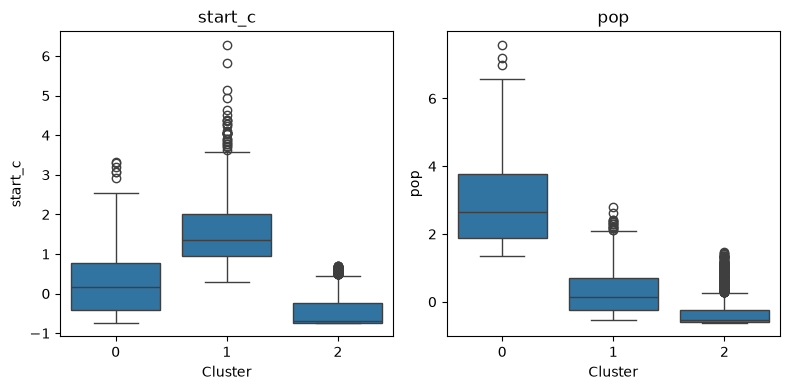

In [15]:
plot_utils.Plot.plot_cluster_feature_boxplots(df=clust_res_1, features=["start_c", "pop"], figsize=(8, 4))
plt.show()

In [39]:
for c in (0, 1, 2):
    print("CLUSTER", c)
    print(clust_res_1[clust_res_1["cluster"] == c][["start_c", "pop"]].describe().loc[["25%", "75%"]])

CLUSTER 0
      start_c       pop
25% -0.404991  1.893117
75%  0.784516  3.765223
CLUSTER 1
      start_c       pop
25%  0.948586 -0.249796
75%  2.015041  0.690428
CLUSTER 2
      start_c       pop
25% -0.733131 -0.602529
75% -0.240921 -0.252180


### 2.2 Vehicles derived from clusters' trajectories and features visualization

In [16]:
v_clusters_res_1 = cluster_utils.Clustering.map_vehicles_to_cell_clusters(
    trace=trace, clustered_celldf=clust_res_1)
# Moving index to column
v_clusters_res_1.reset_index(names="vehicle_id", inplace=True)

In [17]:
v_clusters_res_1.head()

,vehicle_id,cluster,certainty
0,0,0,0.607143
1,1,2,0.515152
2,2,2,0.600000
3,3,1,0.434783
4,4,2,0.540541


In [18]:
v_clusters_res_1[["vehicle_id", "cluster"]].to_csv("vc_from_c.csv", index=False, sep=";", header=False)

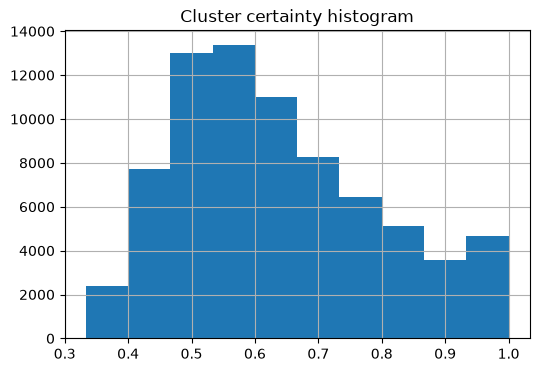

In [19]:
v_clusters_res_1["certainty"].hist(figsize=(6, 4))
plt.title("Cluster certainty histogram")
plt.show()

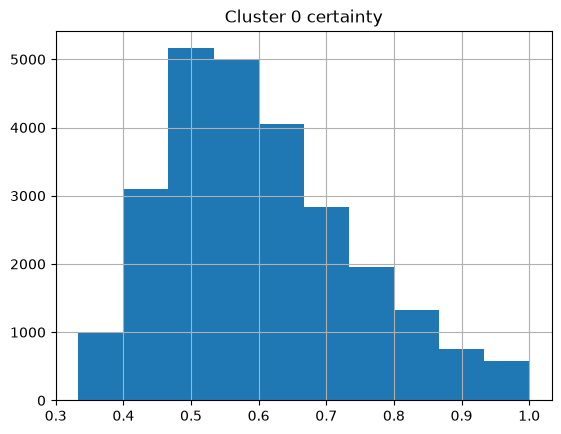

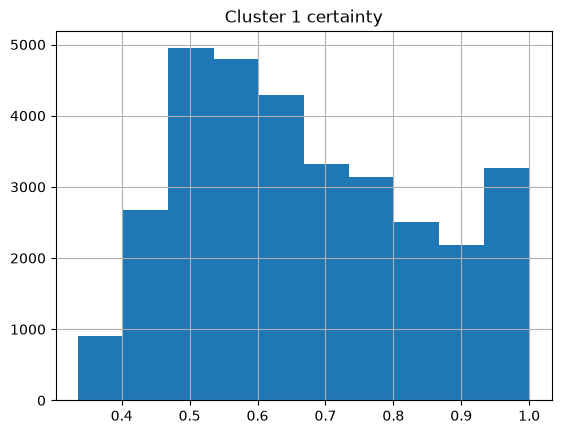

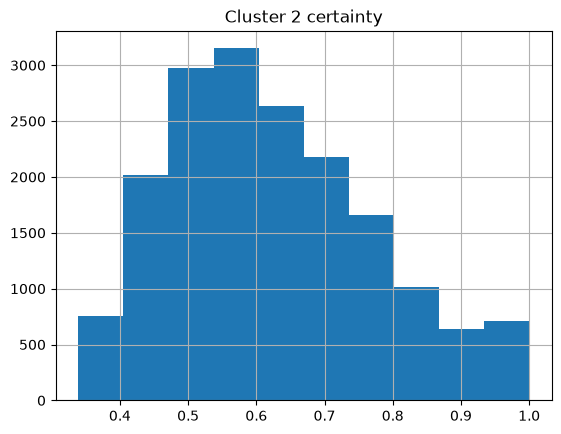

In [20]:
for cluster_id in (0, 1, 2):
    v_clusters_res_1[v_clusters_res_1["cluster"] == cluster_id]["certainty"].hist()
    plt.title(f"Cluster {cluster_id} certainty")
    plt.show()

In [21]:
v_clusters_res_1["cluster"].value_counts() / len(v_clusters_res_1)

cluster
1    0.424029
0    0.341080
2    0.234891
Name: count, dtype: float64


Cluster 0
[+] Certainty Threshold: 0.7
[+] Num Vehicles: 6043 (8.00 %)

Cluster 1
[+] Certainty Threshold: 0.7
[+] Num Vehicles: 12911 (17.10 %)

Cluster 2
[+] Certainty Threshold: 0.7
[+] Num Vehicles: 5148 (6.82 %)


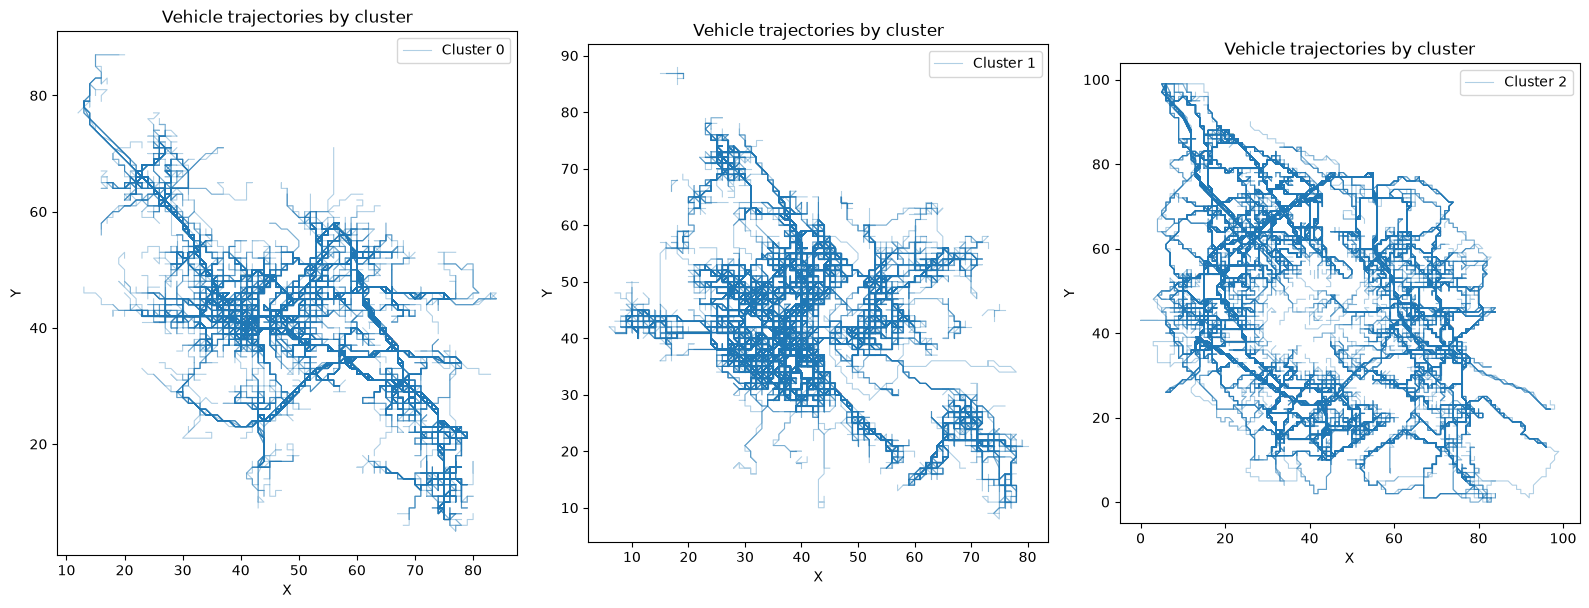

In [22]:
certainty_threshold = 0.7

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(16, 6))
for cluster_id in sorted(v_clusters_res_1["cluster"].unique()):

    to_plot = v_clusters_res_1[(v_clusters_res_1["cluster"] == cluster_id)
                               & (v_clusters_res_1["certainty"] >= certainty_threshold)]

    print()
    print(f"Cluster {cluster_id}")
    print(f"[+] Certainty Threshold: {certainty_threshold}")
    print(f"[+] Num Vehicles: {len(to_plot)} ({100 * len(to_plot)/trace["vehicle_id"].nunique():.2f} %)")
    plot_utils.Plot.plot_trajectories_by_cluster(
        trace=trace, clusters=to_plot, ax=ax[cluster_id])

plt.tight_layout()
plt.savefig("veic_clust_from_c.png")
plt.show()


Cluster 0
[+] Certainty Threshold: 0.8
[+] Num Vehicles: 2651 (3.51 %)

Cluster 1
[+] Certainty Threshold: 0.8
[+] Num Vehicles: 8233 (10.90 %)

Cluster 2
[+] Certainty Threshold: 0.8
[+] Num Vehicles: 2462 (3.26 %)


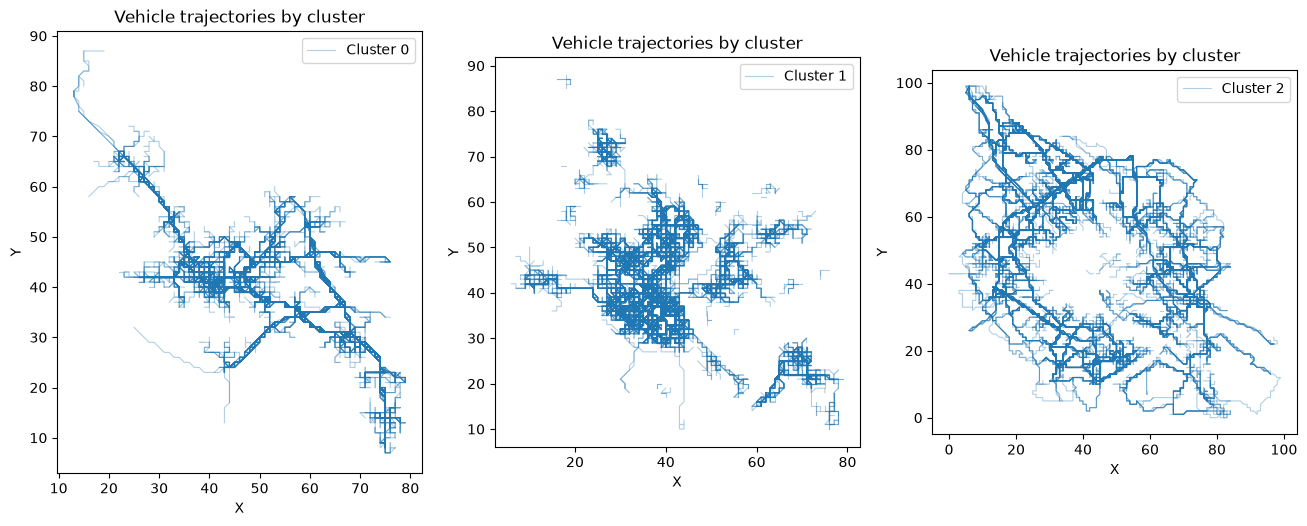

In [20]:
certainty_threshold = 0.8

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(16, 6))
for cluster_id in sorted(v_clusters_res_1["cluster"].unique()):

    to_plot = v_clusters_res_1[(v_clusters_res_1["cluster"] == cluster_id)
                               & (v_clusters_res_1["certainty"] >= certainty_threshold)]

    print()
    print(f"Cluster {cluster_id}")
    print(f"[+] Certainty Threshold: {certainty_threshold}")
    print(f"[+] Num Vehicles: {len(to_plot)} ({100 * len(to_plot)/trace["vehicle_id"].nunique():.2f} %)")
    plot_utils.Plot.plot_trajectories_by_cluster(
        trace=trace, clusters=to_plot, ax=ax[cluster_id])

plt.show()

In [41]:
for c in (0, 1, 2):
    print("CLUSTER", c)
    print(v_clusters_res_1[v_clusters_res_1["cluster"] == c].describe().loc[["25%", "75%"]])

CLUSTER 0
     vehicle_id  cluster  certainty
25%     17214.0      0.0   0.500000
75%     58318.0      0.0   0.690476
CLUSTER 1
     vehicle_id  cluster  certainty
25%     20046.0      1.0   0.529412
75%     55870.0      1.0   0.800000
CLUSTER 2
     vehicle_id  cluster  certainty
25%    19338.25      2.0   0.511111
75%    56782.75      2.0   0.722222


In [44]:
v_features_and_clusters_1 = v_df.merge(v_clusters_res_1, on="vehicle_id", how="inner")
v_features_and_clusters_1.head()

,vehicle_id,trip_duration,trip_length,trip_speed,radius_of_gyration,entropy,cluster,certainty
0,0,-0.956085,-0.685207,0.686673,-0.692637,-0.222071,0,0.607143
1,1,0.205044,0.323697,0.378576,0.711783,0.675063,2,0.515152
2,2,-0.589413,-0.101105,1.462592,0.004162,0.379546,2,0.600000
3,3,-1.108865,-0.791407,0.965864,-0.744924,-0.430485,1,0.434783
4,4,0.449492,0.642298,0.556510,0.867275,0.947794,2,0.540541


In [46]:
for c in (0, 1, 2):
    print("CLUSTER", c)
    print(v_features_and_clusters_1[v_features_and_clusters_1["cluster"] == c][["trip_duration", "entropy", "radius_of_gyration"]].describe().loc[["25%", "75%"]])

CLUSTER 0
     trip_duration   entropy  radius_of_gyration
25%      -0.344964 -0.224145           -0.492598
75%       0.968945  1.008305            1.113167
CLUSTER 1
     trip_duration   entropy  radius_of_gyration
25%      -0.956085 -0.972215           -0.912865
75%       0.113376  0.209257           -0.168109
CLUSTER 2
     trip_duration   entropy  radius_of_gyration
25%      -0.650525 -0.257131           -0.538443
75%       0.724497  1.001621            0.885051


In [1]:
certainty_threshold = 0.4

plot_utils.Plot.plot_cluster_feature_boxplots(
    figsize=(20, 4), df=v_features_and_clusters_1[v_features_and_clusters_1["certainty"] > certainty_threshold],
    features=["trip_speed", "trip_length", "trip_duration", "entropy", "radius_of_gyration"])
plt.show()

NameError: name 'plot_utils' is not defined

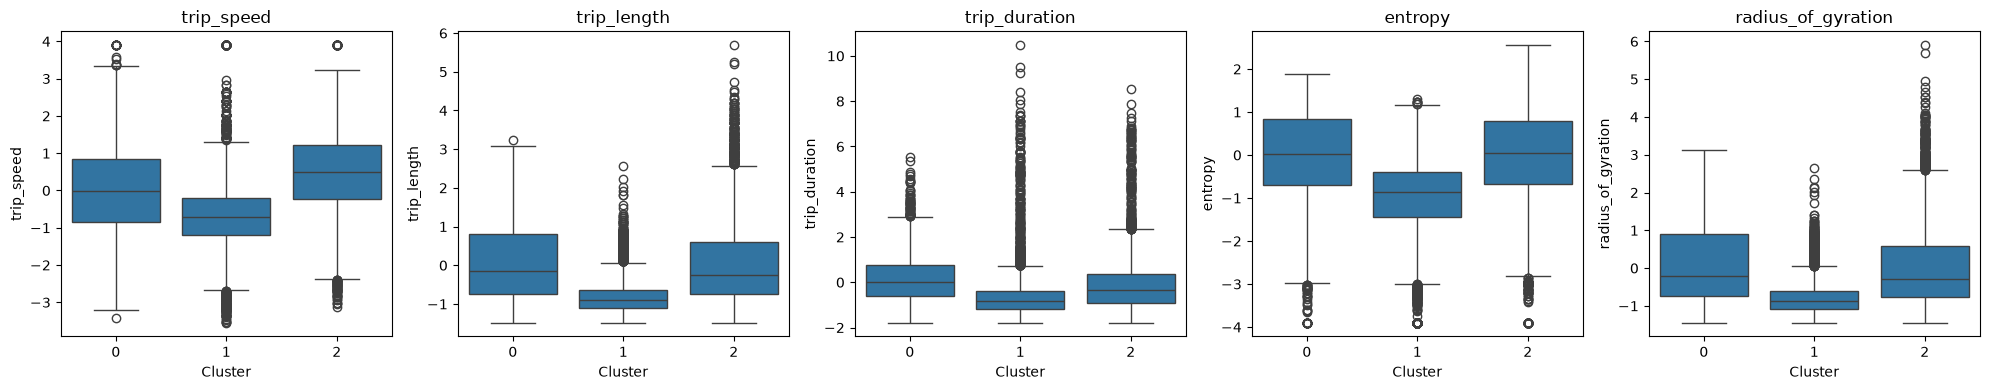

In [23]:
certainty_threshold = 0.7

plot_utils.Plot.plot_cluster_feature_boxplots(
    figsize=(20, 4), df=v_features_and_clusters_1[v_features_and_clusters_1["certainty"] > certainty_threshold],
    features=["trip_speed", "trip_length", "trip_duration", "entropy", "radius_of_gyration"])
plt.show()

In [43]:
v_features_and_clusters_1

NameError: name 'v_features_and_clusters_1' is not defined

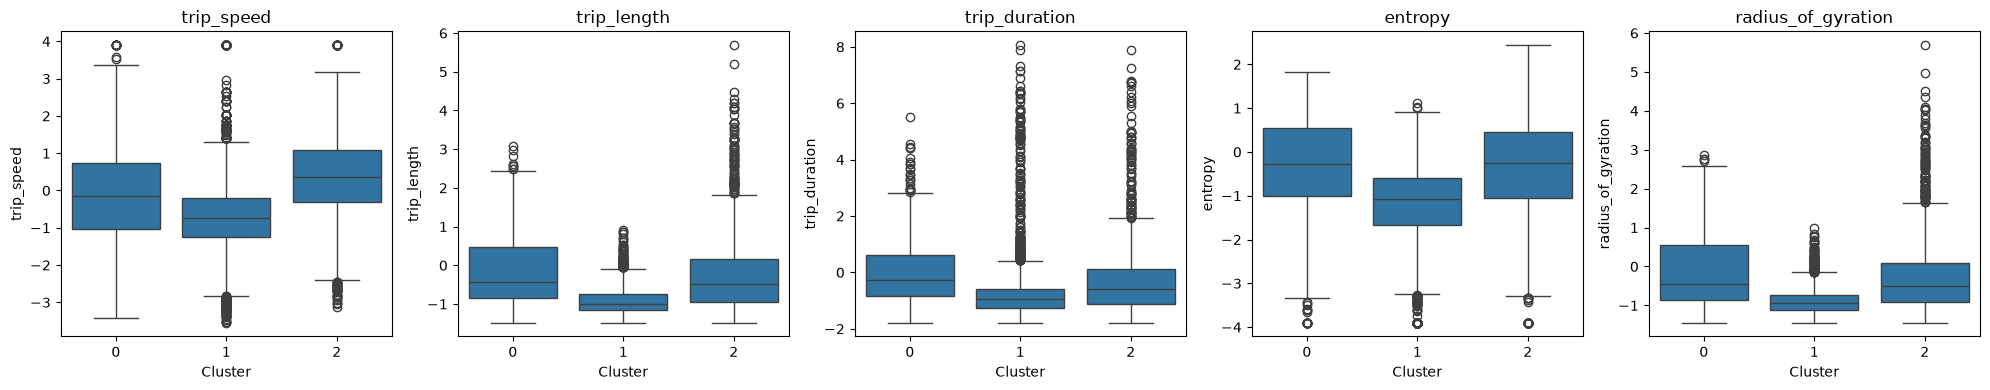

In [24]:
certainty_threshold = 0.8

plot_utils.Plot.plot_cluster_feature_boxplots(
    figsize=(20, 4), df=v_features_and_clusters_1[v_features_and_clusters_1["certainty"] > certainty_threshold],
    features=["trip_speed", "trip_length", "trip_duration", "entropy", "radius_of_gyration"])
plt.show()

## **3. Selected clustering 2: destiny oriented**

- Features: (end_c, pop)
- k: 3

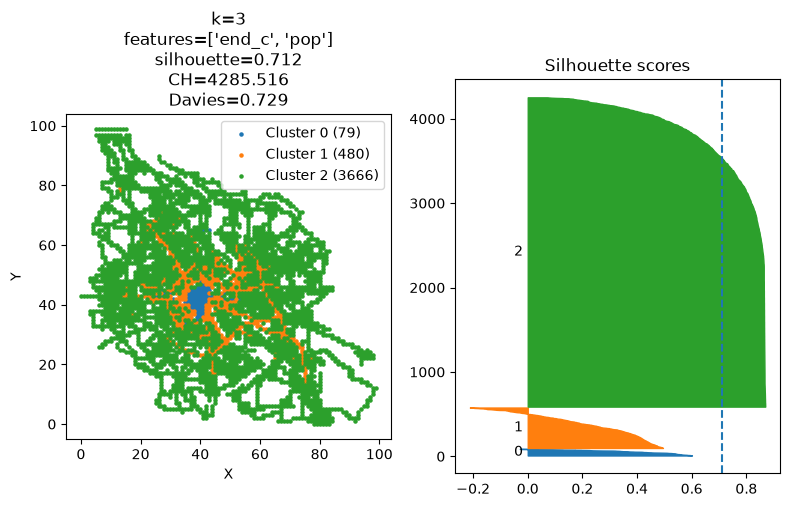

In [25]:
clust_res_2 = cluster_utils.Clustering.run_kmeans(
    df=cell_df, features=["end_c", "pop"], k=3, n_runs=100)[0]
cluster_utils.Clustering.plot_celldf_clustering_result(
    result_df=clust_res_2, features=["end_c", "pop"], figsize=(8, 5))
plt.show()

### 3.1 Cells' clusters features distribution

- One cluster dominates in terms of destiny (blue)
- One cluster dominates in terms of density/popularity (orange)
- The third is behind the two first (green margin region)

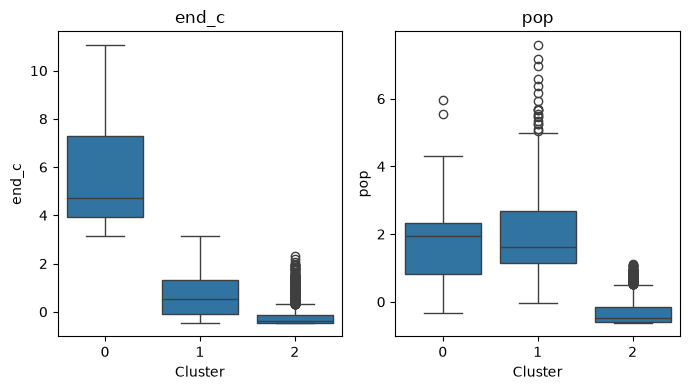

In [26]:
plot_utils.Plot.plot_cluster_feature_boxplots(df=clust_res_2, features=["end_c", "pop"], figsize=(7, 4))
plt.show()

### 3.2 Vehicles derived from clusters' trajectories and features visualization

In [27]:
v_clusters_res_2 = cluster_utils.Clustering.map_vehicles_to_cell_clusters(
    trace=trace, clustered_celldf=clust_res_2)
# Moving index to column
v_clusters_res_2.reset_index(names="vehicle_id", inplace=True)

In [28]:
v_clusters_res_2.head()

,vehicle_id,cluster,certainty
0,0,1,0.964286
1,1,2,0.803030
2,2,2,0.800000
3,3,2,0.565217
4,4,2,0.581081


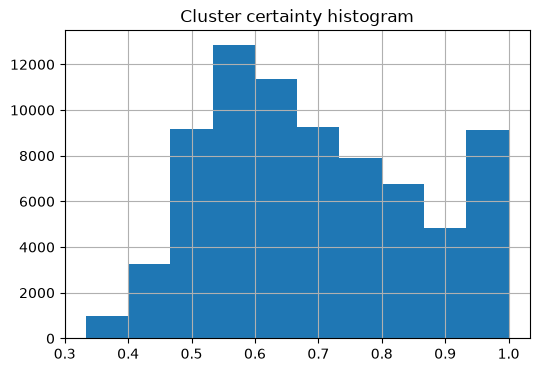

In [29]:
v_clusters_res_2["certainty"].hist(figsize=(6, 4))
plt.title("Cluster certainty histogram")
plt.show()


Cluster 0
[+] Certainty Threshold: 0.7
[+] Num Vehicles: 2961 (3.92 %)

Cluster 1
[+] Certainty Threshold: 0.7
[+] Num Vehicles: 13372 (17.71 %)

Cluster 2
[+] Certainty Threshold: 0.7
[+] Num Vehicles: 17232 (22.82 %)


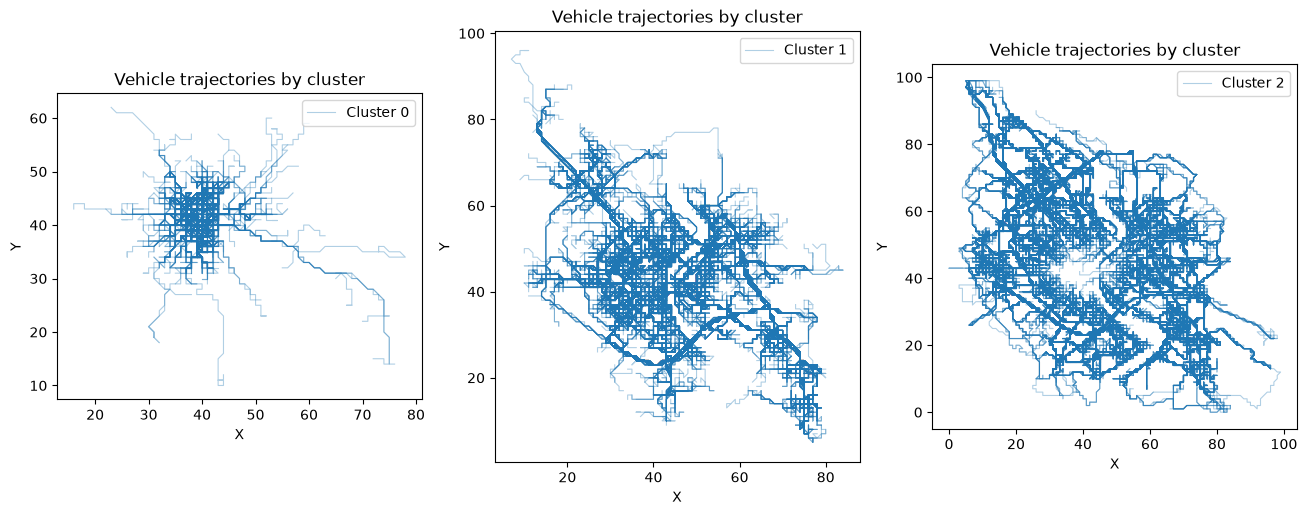

In [30]:
certainty_threshold = 0.7

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(16, 6))
for cluster_id in sorted(v_clusters_res_2["cluster"].unique()):

    to_plot = v_clusters_res_2[(v_clusters_res_2["cluster"] == cluster_id)
                               & (v_clusters_res_2["certainty"] >= certainty_threshold)]

    print()
    print(f"Cluster {cluster_id}")
    print(f"[+] Certainty Threshold: {certainty_threshold}")
    print(f"[+] Num Vehicles: {len(to_plot)} ({100 * len(to_plot)/trace["vehicle_id"].nunique():.2f} %)")
    plot_utils.Plot.plot_trajectories_by_cluster(
        trace=trace, clusters=to_plot, ax=ax[cluster_id])

plt.show()


Cluster 0
[+] Certainty Threshold: 0.8
[+] Num Vehicles: 2138 (2.83 %)

Cluster 1
[+] Certainty Threshold: 0.8
[+] Num Vehicles: 6259 (8.29 %)

Cluster 2
[+] Certainty Threshold: 0.8
[+] Num Vehicles: 12344 (16.35 %)


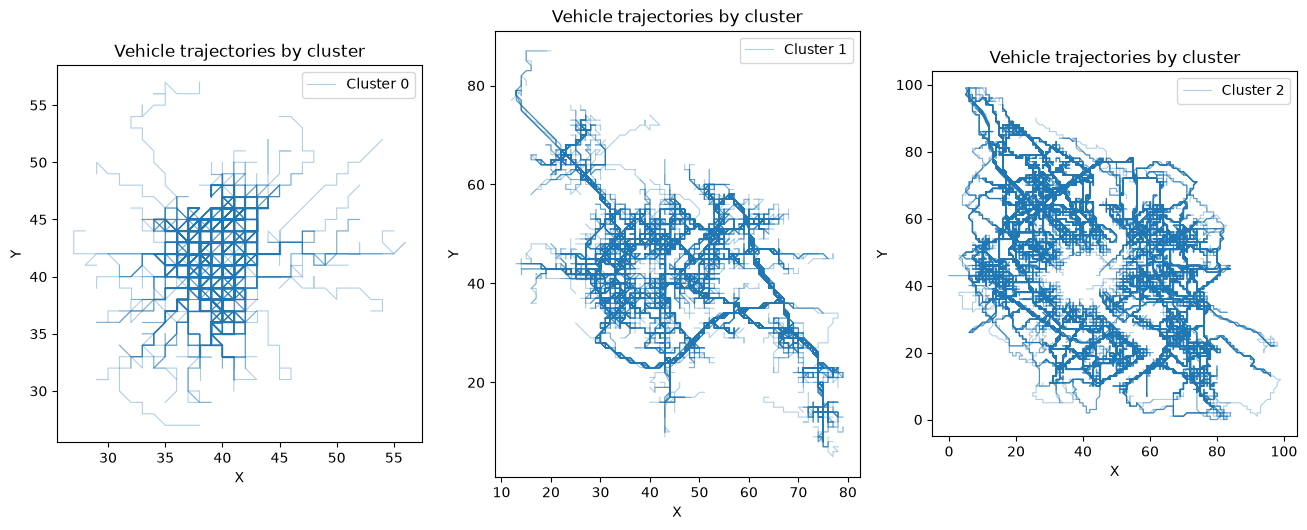

In [31]:
certainty_threshold = 0.8

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(16, 6))
for cluster_id in sorted(v_clusters_res_2["cluster"].unique()):

    to_plot = v_clusters_res_2[(v_clusters_res_2["cluster"] == cluster_id)
                               & (v_clusters_res_2["certainty"] >= certainty_threshold)]

    print()
    print(f"Cluster {cluster_id}")
    print(f"[+] Certainty Threshold: {certainty_threshold}")
    print(f"[+] Num Vehicles: {len(to_plot)} ({100 * len(to_plot)/trace["vehicle_id"].nunique():.2f} %)")
    plot_utils.Plot.plot_trajectories_by_cluster(
        trace=trace, clusters=to_plot, ax=ax[cluster_id])

plt.show()

In [32]:
v_features_and_clusters_2 = v_df.merge(v_clusters_res_2, on="vehicle_id", how="inner")
v_features_and_clusters_2.head()

,vehicle_id,trip_duration,trip_length,trip_speed,radius_of_gyration,entropy,cluster,certainty
0,0,-0.956085,-0.685207,0.686673,-0.692637,-0.222071,1,0.964286
1,1,0.205044,0.323697,0.378576,0.711783,0.675063,2,0.803030
2,2,-0.589413,-0.101105,1.462592,0.004162,0.379546,2,0.800000
3,3,-1.108865,-0.791407,0.965864,-0.744924,-0.430485,2,0.565217
4,4,0.449492,0.642298,0.556510,0.867275,0.947794,2,0.581081


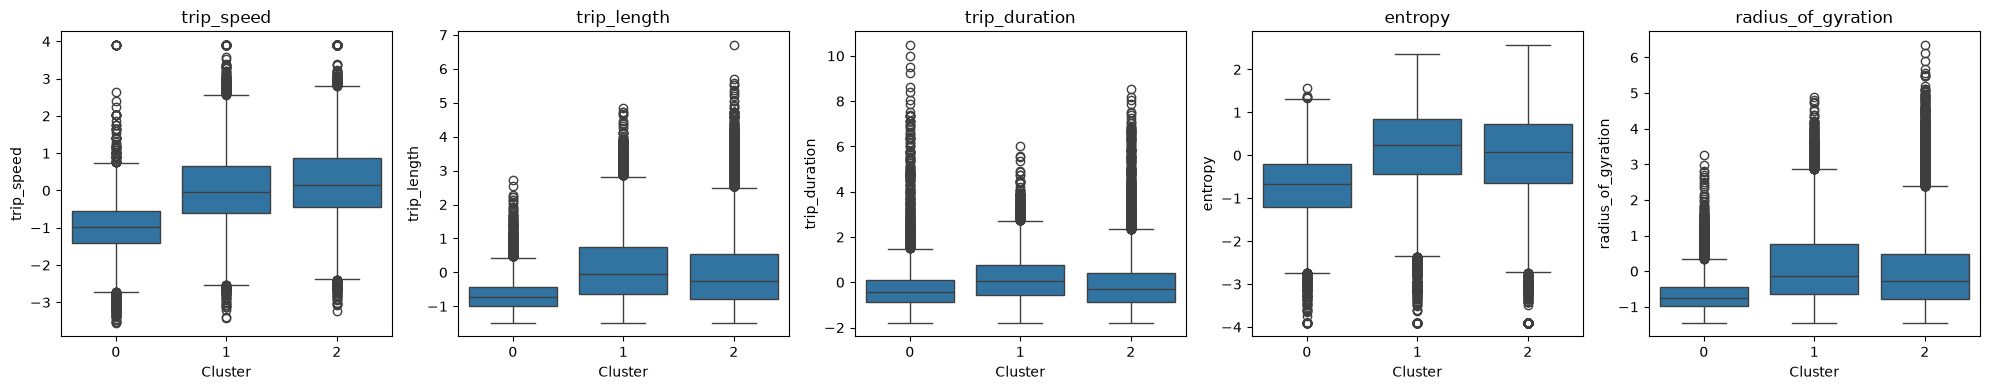

In [33]:
certainty_threshold = 0.4

plot_utils.Plot.plot_cluster_feature_boxplots(
    figsize=(20, 4), df=v_features_and_clusters_2[v_features_and_clusters_2["certainty"] > certainty_threshold],
    features=["trip_speed", "trip_length", "trip_duration", "entropy", "radius_of_gyration"])
plt.show()

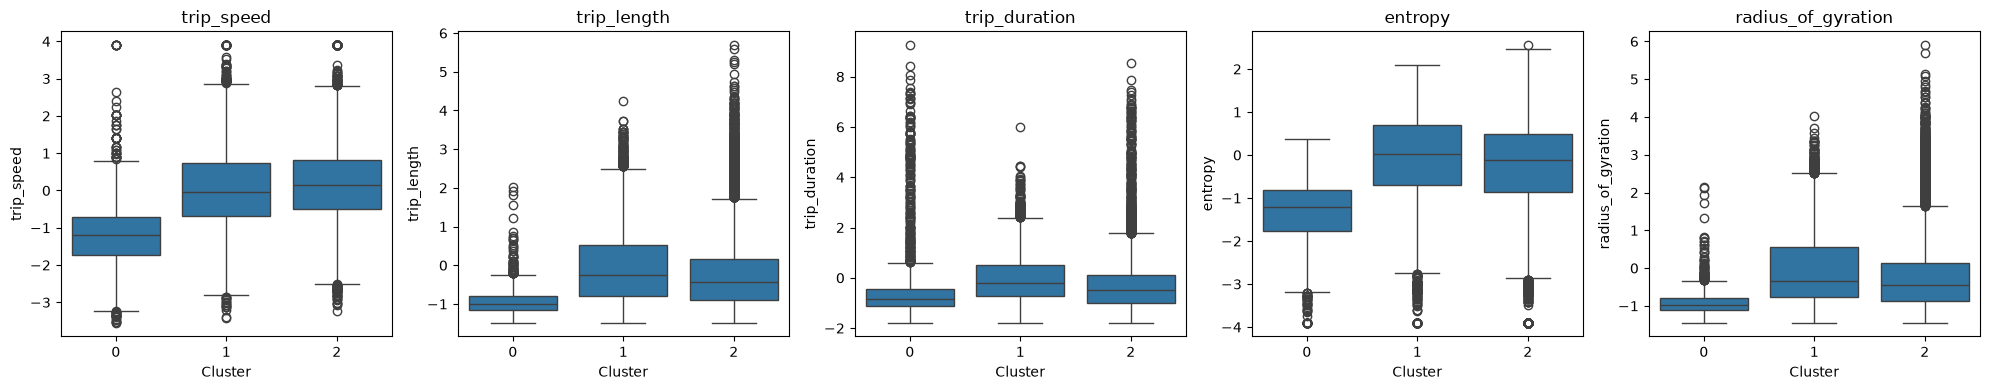

In [34]:
certainty_threshold = 0.7

plot_utils.Plot.plot_cluster_feature_boxplots(
    figsize=(20, 4), df=v_features_and_clusters_2[v_features_and_clusters_2["certainty"] > certainty_threshold],
    features=["trip_speed", "trip_length", "trip_duration", "entropy", "radius_of_gyration"])
plt.show()

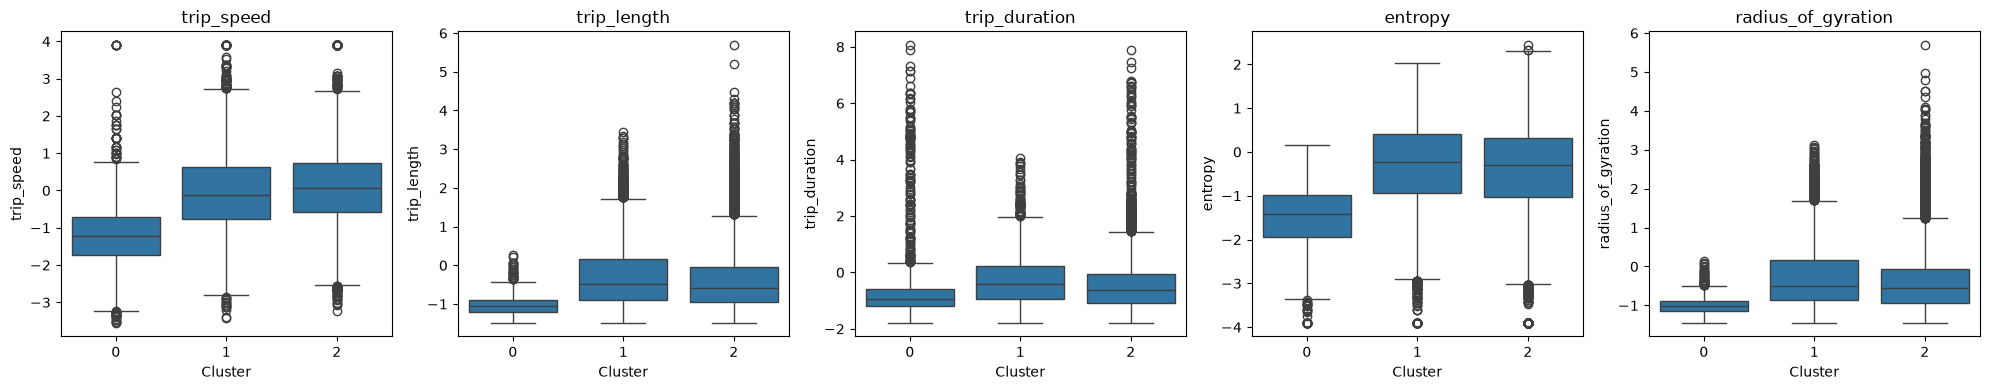

In [35]:
certainty_threshold = 0.8

plot_utils.Plot.plot_cluster_feature_boxplots(
    figsize=(20, 4), df=v_features_and_clusters_2[v_features_and_clusters_2["certainty"] > certainty_threshold],
    features=["trip_speed", "trip_length", "trip_duration", "entropy", "radius_of_gyration"])
plt.show()

## **4. Vehicles' feature pairs**

### 4.1 Entire dataset

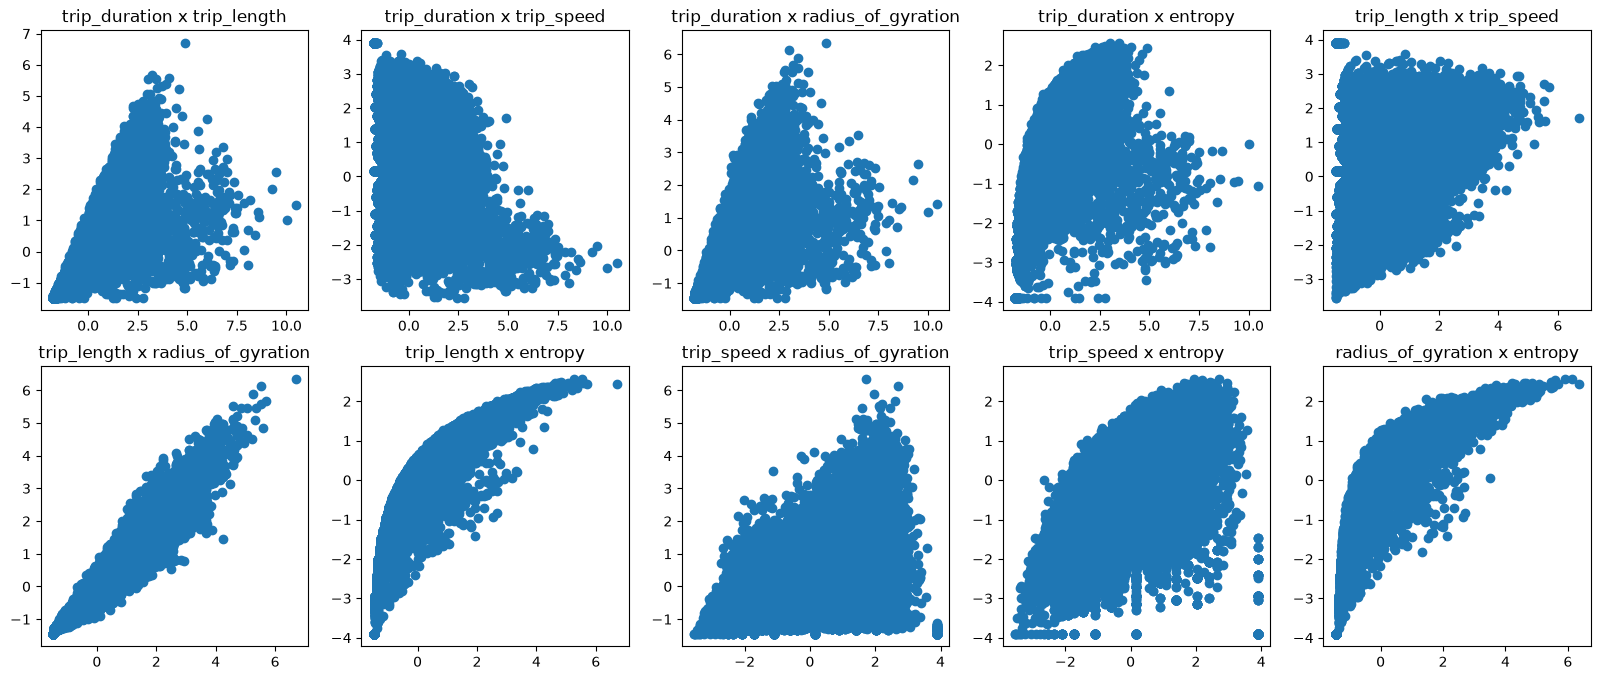

In [36]:
from itertools import combinations

fig, ax = plt.subplots(nrows=2, ncols=5, figsize=(20, 8))
row, col = 0, 0
for comb in combinations(
    iterable=['trip_duration', 'trip_length', 'trip_speed', 'radius_of_gyration', 'entropy'], r=2):

    ax[row, col].scatter(v_df[comb[0]], v_df[comb[1]])
    ax[row, col].set_title(f"{comb[0]} x {comb[1]}")

    col += 1

    if col == 5:
        col = 0
        row += 1

plt.show()

### 4.2 Per cluster (origin oriented)

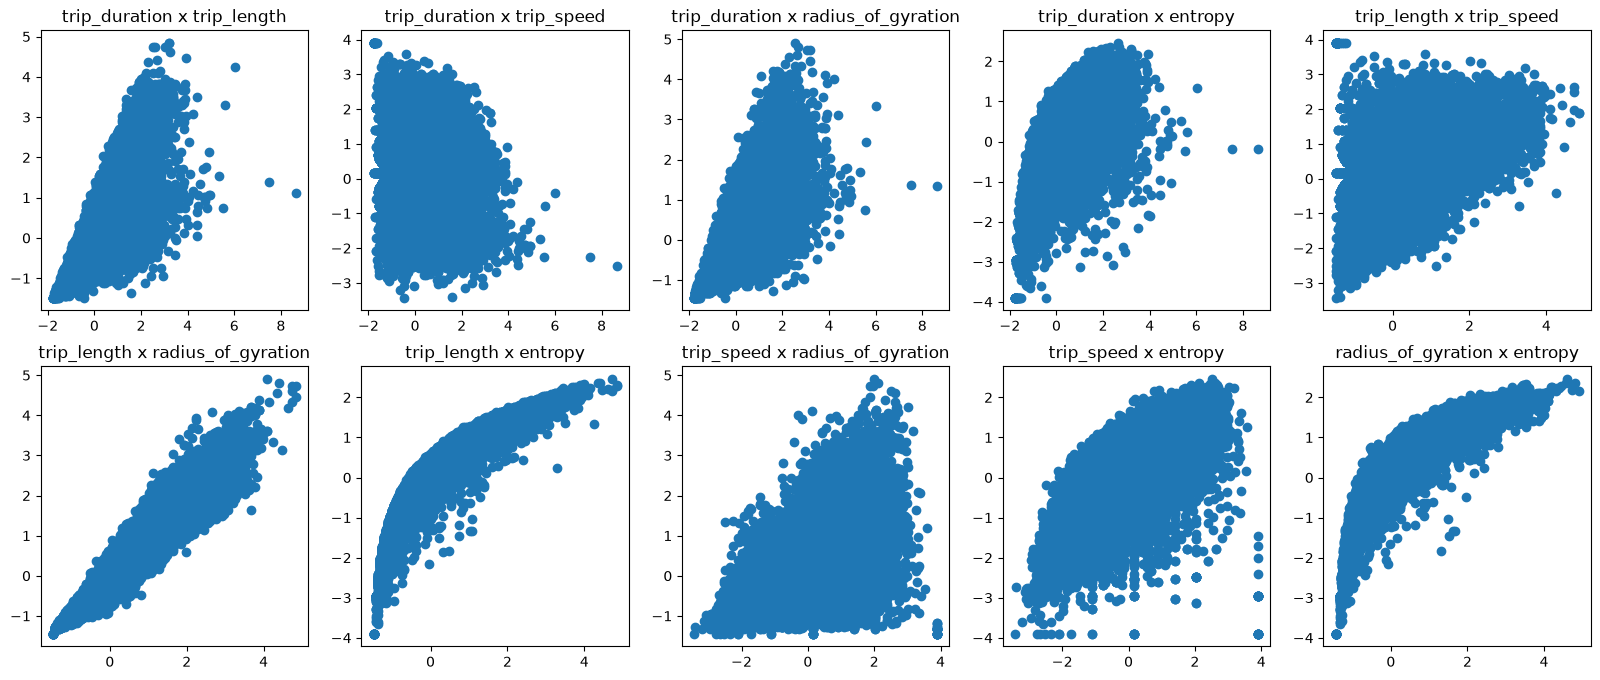

In [37]:
certainty_threshold = 0.0
cluster_id = 0

from itertools import combinations

fig, ax = plt.subplots(nrows=2, ncols=5, figsize=(20, 8))
row, col = 0, 0
for comb in combinations(
    iterable=['trip_duration', 'trip_length', 'trip_speed', 'radius_of_gyration', 'entropy'], r=2):

    df = v_features_and_clusters_1[(v_features_and_clusters_1["cluster"] == cluster_id)
                                   & (v_features_and_clusters_1["certainty"] >= certainty_threshold)]

    ax[row, col].scatter(df[comb[0]], df[comb[1]])
    ax[row, col].set_title(f"{comb[0]} x {comb[1]}")

    col += 1

    if col == 5:
        col = 0
        row += 1

plt.show()

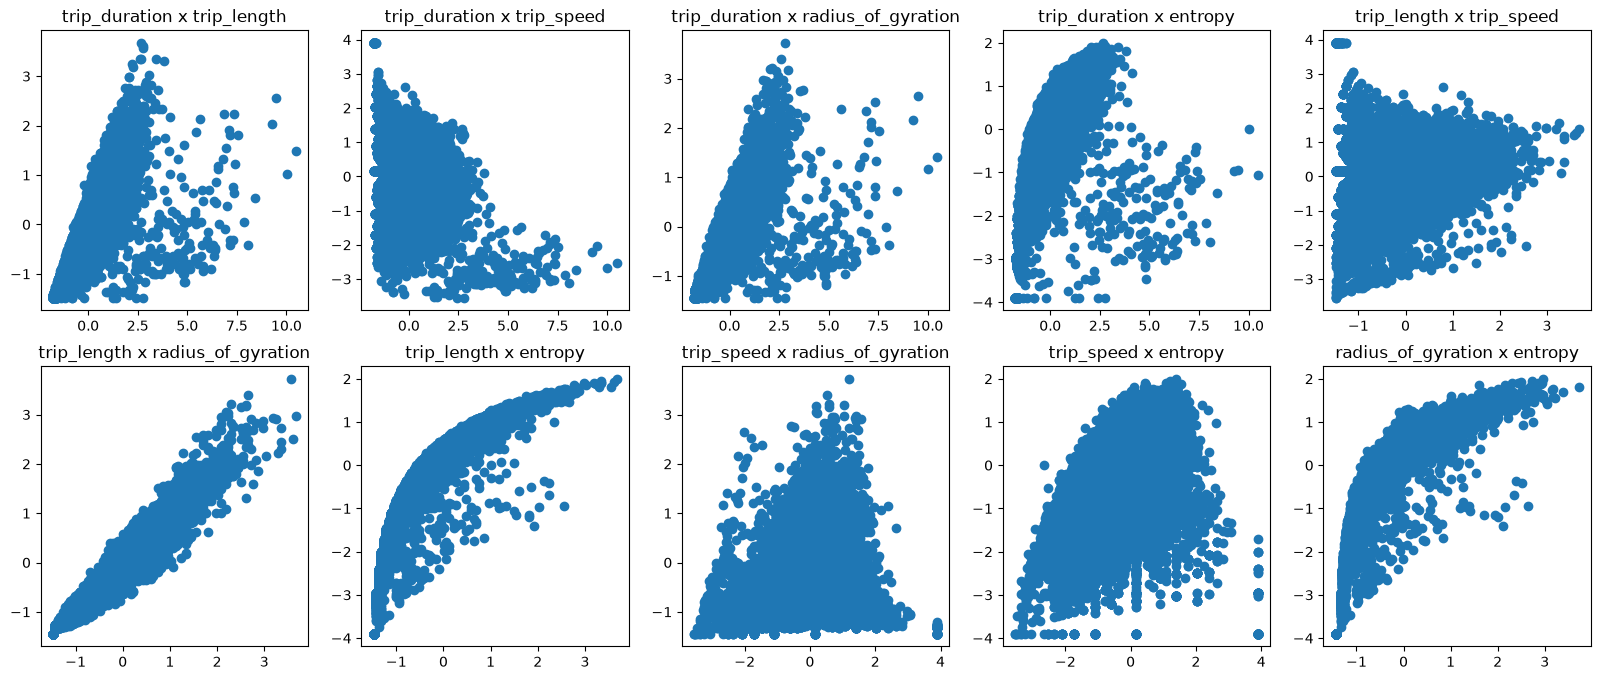

In [38]:
certainty_threshold = 0.0
cluster_id = 1

from itertools import combinations

fig, ax = plt.subplots(nrows=2, ncols=5, figsize=(20, 8))
row, col = 0, 0
for comb in combinations(
    iterable=['trip_duration', 'trip_length', 'trip_speed', 'radius_of_gyration', 'entropy'], r=2):

    df = v_features_and_clusters_1[(v_features_and_clusters_1["cluster"] == cluster_id)
                                   & (v_features_and_clusters_1["certainty"] >= certainty_threshold)]

    ax[row, col].scatter(df[comb[0]], df[comb[1]])
    ax[row, col].set_title(f"{comb[0]} x {comb[1]}")

    col += 1

    if col == 5:
        col = 0
        row += 1

plt.show()

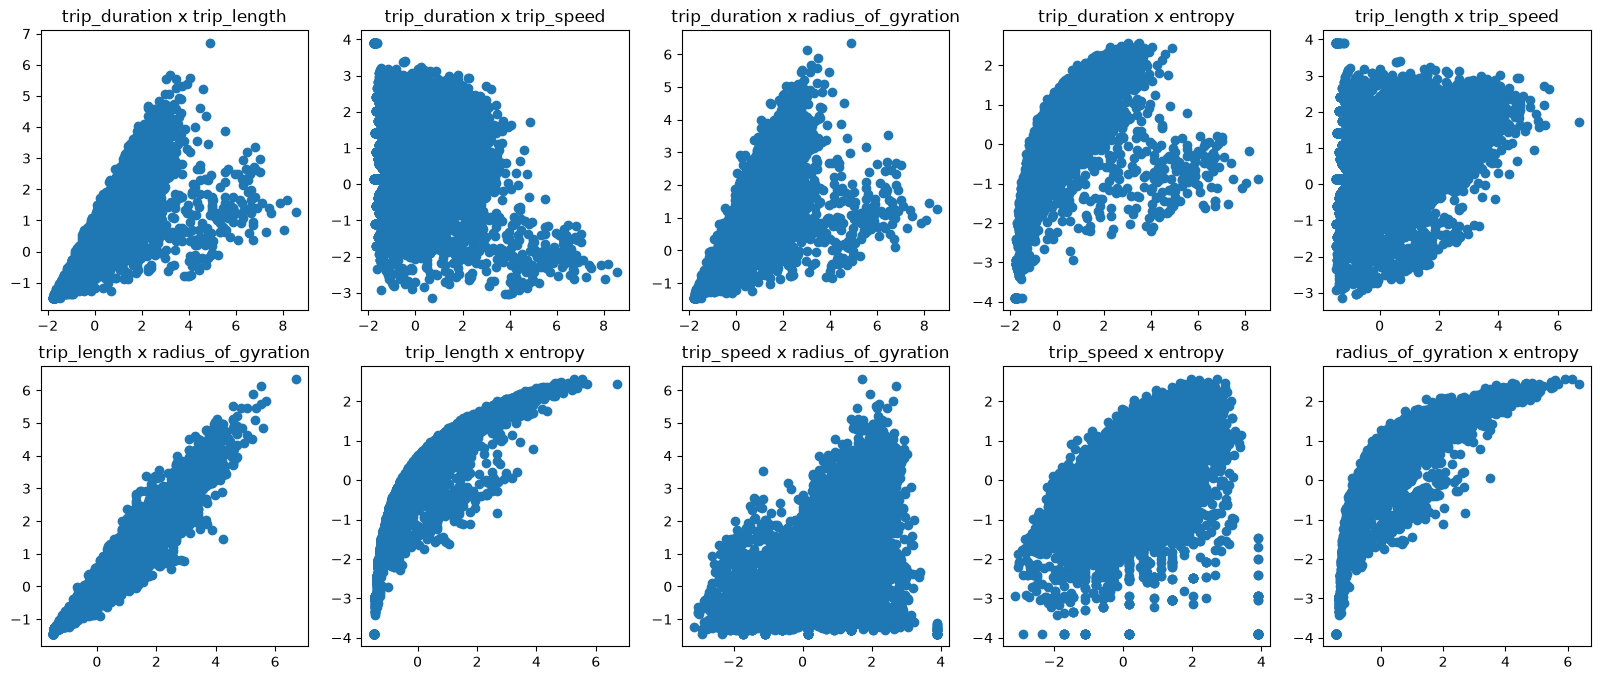

In [39]:
certainty_threshold = 0.0
cluster_id = 2

from itertools import combinations

fig, ax = plt.subplots(nrows=2, ncols=5, figsize=(20, 8))
row, col = 0, 0
for comb in combinations(
    iterable=['trip_duration', 'trip_length', 'trip_speed', 'radius_of_gyration', 'entropy'], r=2):

    df = v_features_and_clusters_1[(v_features_and_clusters_1["cluster"] == cluster_id)
                                   & (v_features_and_clusters_1["certainty"] >= certainty_threshold)]

    ax[row, col].scatter(df[comb[0]], df[comb[1]])
    ax[row, col].set_title(f"{comb[0]} x {comb[1]}")

    col += 1

    if col == 5:
        col = 0
        row += 1

plt.show()

### 4.3 Per cluster (destiny oriented)

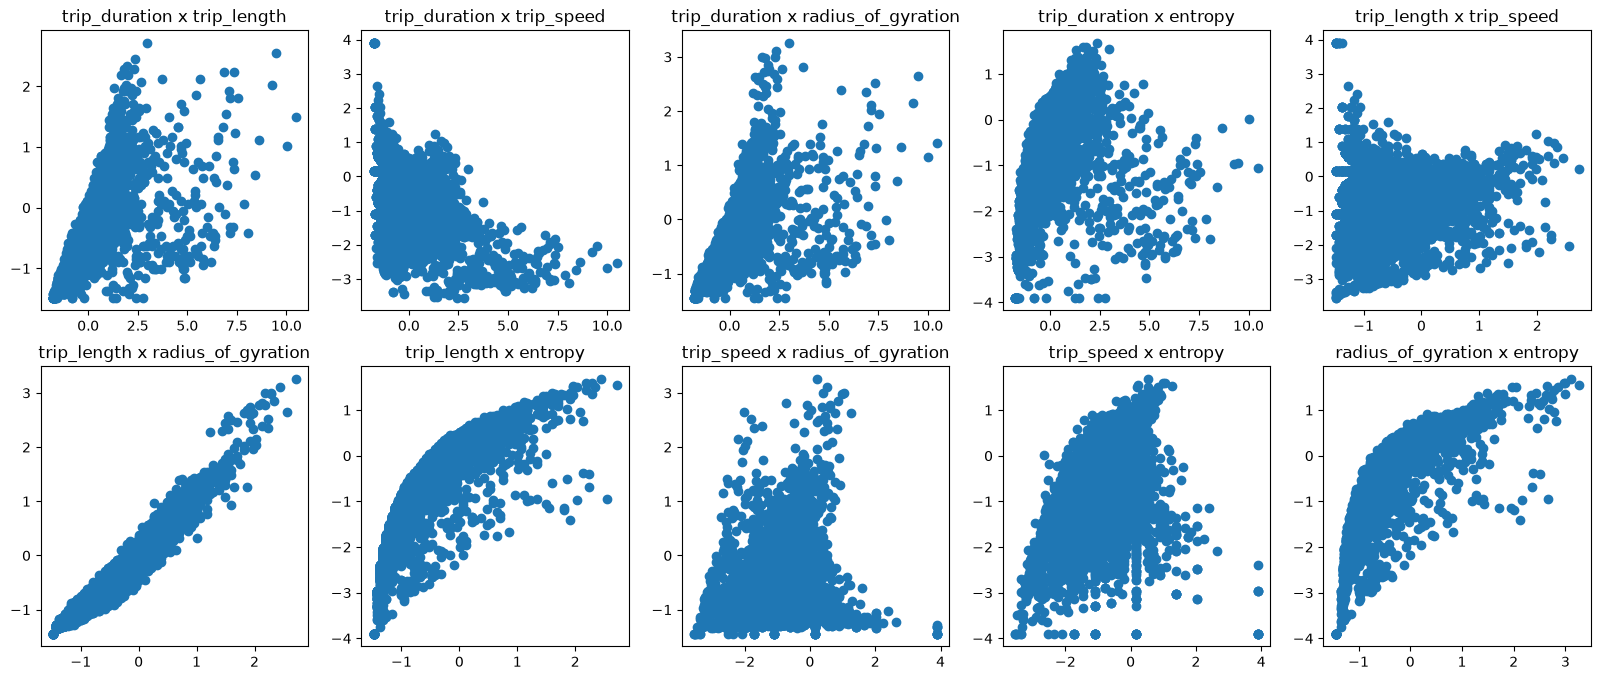

In [40]:
certainty_threshold = 0.0
cluster_id = 0

from itertools import combinations

fig, ax = plt.subplots(nrows=2, ncols=5, figsize=(20, 8))
row, col = 0, 0
for comb in combinations(
    iterable=['trip_duration', 'trip_length', 'trip_speed', 'radius_of_gyration', 'entropy'], r=2):

    df = v_features_and_clusters_2[(v_features_and_clusters_2["cluster"] == cluster_id)
                                   & (v_features_and_clusters_2["certainty"] >= certainty_threshold)]

    ax[row, col].scatter(df[comb[0]], df[comb[1]])
    ax[row, col].set_title(f"{comb[0]} x {comb[1]}")

    col += 1

    if col == 5:
        col = 0
        row += 1

plt.show()

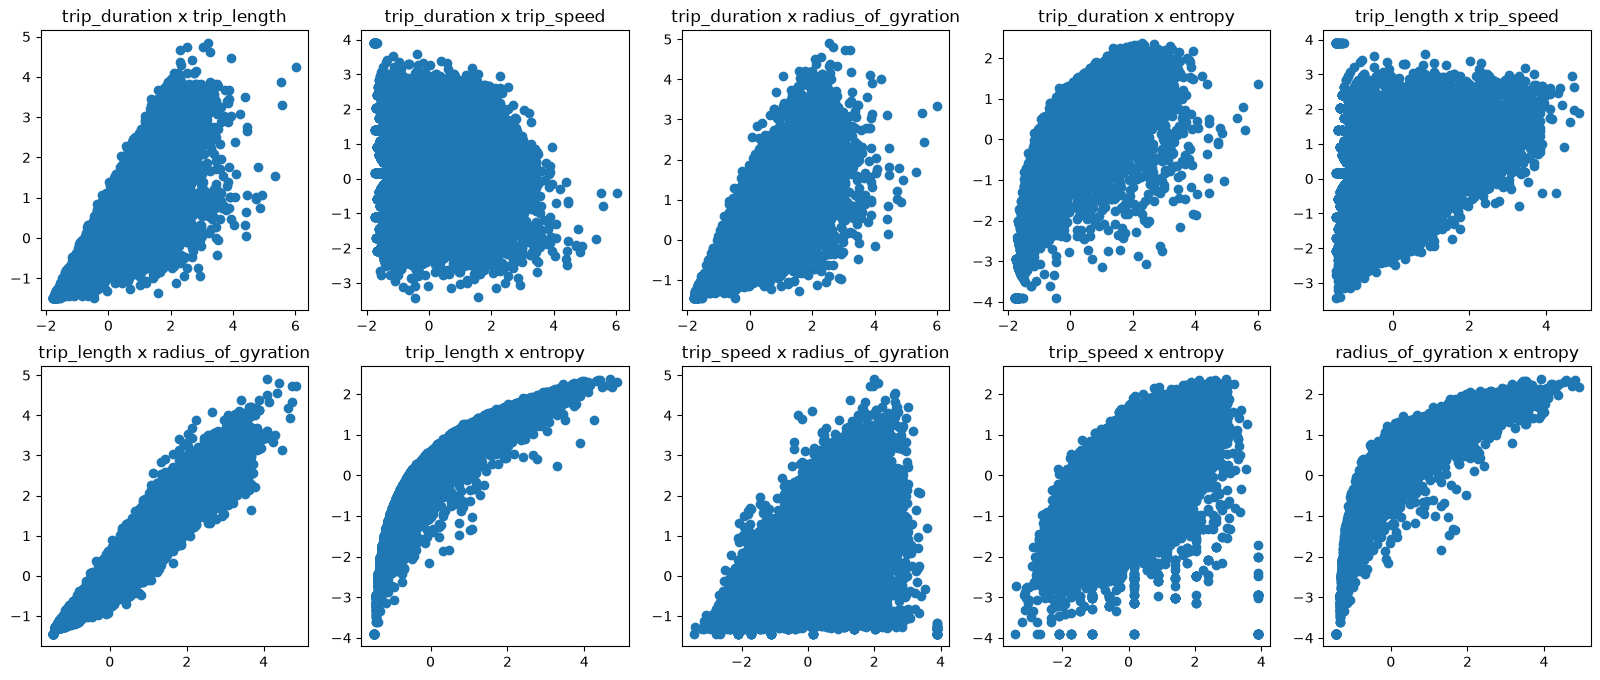

In [41]:
certainty_threshold = 0.0
cluster_id = 1

from itertools import combinations

fig, ax = plt.subplots(nrows=2, ncols=5, figsize=(20, 8))
row, col = 0, 0
for comb in combinations(
    iterable=['trip_duration', 'trip_length', 'trip_speed', 'radius_of_gyration', 'entropy'], r=2):

    df = v_features_and_clusters_2[(v_features_and_clusters_2["cluster"] == cluster_id)
                                   & (v_features_and_clusters_2["certainty"] >= certainty_threshold)]

    ax[row, col].scatter(df[comb[0]], df[comb[1]])
    ax[row, col].set_title(f"{comb[0]} x {comb[1]}")

    col += 1

    if col == 5:
        col = 0
        row += 1

plt.show()

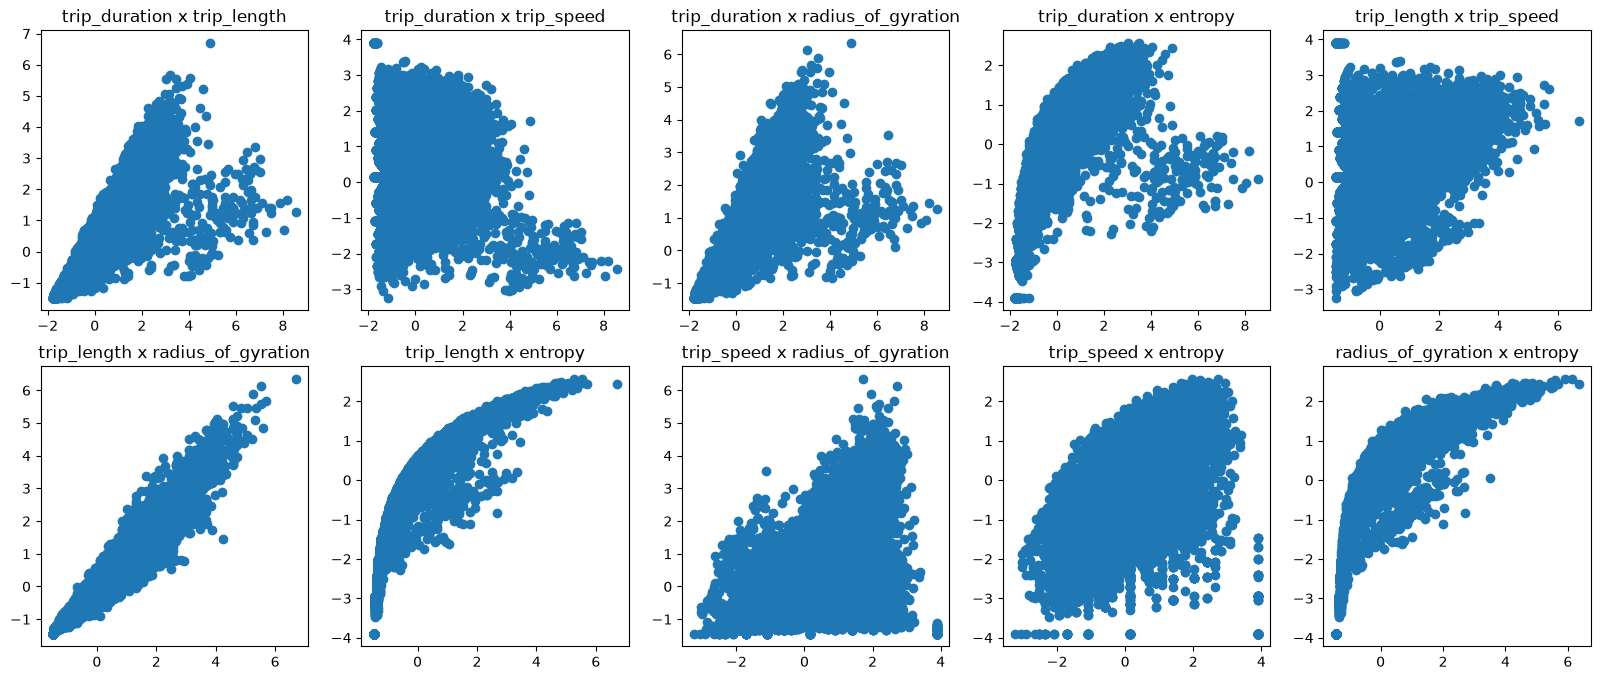

In [42]:
certainty_threshold = 0.0
cluster_id = 2

from itertools import combinations

fig, ax = plt.subplots(nrows=2, ncols=5, figsize=(20, 8))
row, col = 0, 0
for comb in combinations(
    iterable=['trip_duration', 'trip_length', 'trip_speed', 'radius_of_gyration', 'entropy'], r=2):

    df = v_features_and_clusters_2[(v_features_and_clusters_2["cluster"] == cluster_id)
                                   & (v_features_and_clusters_2["certainty"] >= certainty_threshold)]

    ax[row, col].scatter(df[comb[0]], df[comb[1]])
    ax[row, col].set_title(f"{comb[0]} x {comb[1]}")

    col += 1

    if col == 5:
        col = 0
        row += 1

plt.show()

## **Conclusions**

- Cells' clusters show a clear behavior separation that is explainable
- Vehicles' features distribution per induced cluster are reasonable
- Some Vehicles induced clusters show a more clear separation between some features, notably entropy, trip duration and radius of gyration
- Better pick only cells' features (start_c, pop) to analyze for now; (end_c, pop) is redundant in some sense (when comparing vehicles and cells features, they are complementary)